# P2 Notebook 1 — Dataset Construction (Scraping)

**Classes:** `leopard`, `jaguar`, `cheetah`, `ocelot`, `serval`

This notebook builds a labeled image dataset of five spotted wild cats by scraping Bing image
search, and keeps an exact record of what was collected. It starts from the provided
`ddgs_image_scraper.ipynb` and keeps that notebook's structure; the provided module
`ddgs_scraper.py` sits beside it and is imported, not modified.

Every image dataset used in earlier units arrived clean. This one will not — web search for
"jaguar" returns cars, "leopard" returns fabric prints, "ocelot" and "serval" return video-game
and anime characters, and the same photo turns up under more than
one query. This notebook only collects and accounts for the images; judging what is actually in
them is Notebook 2's job.

Scraped images are copyrighted by whoever made them. They are used here for coursework only, are
**not** committed to the repo, and are **not** redistributed. They live in a local data folder
outside the repo; `data/P2_manifest.csv` (URLs and labels, no images) is the only record of the
dataset that goes into the repo.

## This notebook covers

1. What the scraper does
2. Declaring the classes and queries
3. Running the scraper
4. Accounting for what came back
5. A first look at the images
6. Turning the records into a manifest

**Prerequisites:** none — this is the first notebook of P2.

**Dataset:** built here from Bing image search, via the `ddgs` package.

**References:** <https://pypi.org/project/ddgs/>

In [1]:
import contextlib
import io
import shutil
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

pd.set_option('display.max_columns', 100)
pd.set_option('display.max_rows', 100)

plt.style.use('dark_background')

import warnings
warnings.filterwarnings('ignore')

# Project folder: holds this notebook, ddgs_scraper.py, and data/ for the manifest.
# Set explicitly so the import and the manifest path work wherever Jupyter was started.
PROJECT_DIR = Path.home() / 'P2_Images'

# Images go OUTSIDE the project folder, so none can end up in the repo.
IMAGE_DIR = Path.home() / 'MSDS565_data' / 'P2_images'

# The scraper is the provided ddgs_scraper.py in PROJECT_DIR, imported unmodified.
import sys
sys.path.insert(0, str(PROJECT_DIR))
import ddgs_scraper

print('project folder:', PROJECT_DIR)
print('image folder:  ', IMAGE_DIR)

project folder: C:\Users\grego\P2_Images
image folder:   C:\Users\grego\MSDS565_data\P2_images


## 1. What the scraper does

`ddgs_scraper.py` wraps the `ddgs` package, which queries web image search. By default it asks Bing
Images directly — the same index DuckDuckGo Images draws its results from — because that is the
backend that works reliably (see `backend` in section 3). The pieces you will actually call are:

| Function | What it does |
|---|---|
| `search_images(query, ...)` | One search, paged until it has enough results. Returns raw result records — image URL, page URL, title, reported size |
| `download_image(url, ...)` | Fetches one URL and returns an RGB PIL image, or `None` if it isn't one |
| `passes_image_filters(img, ...)` | Checks a downloaded image against size and aspect-ratio limits |
| `scrape_class(label, queries, ...)` | All queries for one class, into one folder |
| `build_image_dataset(class_queries, ...)` | Every class. **This is the one you call.** |

Two things the scraper deliberately does *not* do, because they are your job in Notebook 2:
it does not check for duplicate images, and it does not judge whether the picture is actually of
the thing you searched for.

Read the module before running it. The arguments below are not magic numbers and you will be asked
to defend them.

In [2]:
# The filters every downloaded image has to pass. Both are measured on the image
# that actually arrived, not on the size the search engine claimed.
help(ddgs_scraper.build_image_dataset)

Help on function build_image_dataset in module ddgs_scraper:

build_image_dataset(class_queries: dict, save_dir: str | pathlib.Path, images_per_class: int = 250, results_per_query: int = 200, aspect_ratio_range: tuple = (0.5, 2.0), min_resolution: tuple = (200, 200), per_image_timeout: int = 10, backend: str = 'bing', safesearch: str = 'moderate', region: str = 'us-en', require_query_match: bool = True, query_delay: tuple = (2.0, 5.0), continue_on_error: bool = True, verbose: bool = True) -> tuple[list[dict], dict]
    Download a labeled image dataset from an image search engine.

    One folder per class is created inside save_dir. Every class may have
    several search queries, and results from all of a class's queries land in
    the same folder — using several queries per class is how you get a class
    that looks like the whole category instead of one narrow slice of it.
    Every query is used: downloads take turns between a class's queries, so
    each supplies a roughly equal

## 2. Declaring the classes and queries

### 2.1 The classes: leopard, jaguar, cheetah, ocelot, serval

The five classes are spotted wild cats that are easy to mix up, because all five are tan-to-golden
cats covered in black markings. Three are big cats (leopard, jaguar, cheetah). Two are smaller cats
(ocelot, serval), each chosen because it closely resembles one of the big cats. Coat pattern, build and
face tell them apart:

| Class | Coat pattern | Build | Face / head | Range |
|---|---|---|---|---|
| `cheetah` | Solid, round, single black **spots** | Large, slender, long-legged, deep chest | Small round head; black "tear marks" from eye to mouth | Africa |
| `serval` | Solid **spots**, merging into **bars and stripes** along the neck and back | Medium, extremely long legs, short tail | Very small head with **huge upright ears** | Africa |
| `leopard` | **Rosettes**: small, open, tightly packed rings | Large, long body, medium legs | No tear marks | Africa, Asia |
| `jaguar` | **Rosettes with a dot inside**, larger and wider spaced | Large, stocky and heavy-set, short thick legs | Very broad head | Americas |
| `ocelot` | **Elongated, chain-like blotches** with darker edges, running in lines along the body | Small (house-cat to dog size), low and compact | Two black stripes on each cheek; large eyes | Americas |

The pairs that look alike are the point of the design. Each small cat has a big-cat lookalike:
**serval ↔ cheetah** (solid spots, long legs, tawny) and **ocelot ↔ jaguar/leopard**
(open-centred markings). Size, which would separate them instantly in real life, is usually invisible in a
photo, because there is rarely anything in the frame to give scale.

The labels contain no spaces, so they work as folder names and filename prefixes without
any special handling.

### 2.2 Justification against the four constraints

**3–10 classes.** Five classes. That is enough for a 5×5 confusion matrix with several plausible
confusions to compare, rather than one. It is still few enough to scrape and hand-clean in the time available.
The scrape is spread over more than one sitting (section 3.3).

**At least 200 usable images per class after cleaning.** All five are heavily photographed by wildlife
photographers, safaris and zoos. Ocelots and servals are photographed less than the big cats, but are
common zoo animals, and servals are also popular in the exotic-pet trade. The bigger risk is
*contamination*, because each search term also means something else, so we scrape 400 per class to leave
room for a large loss in Notebook 2:

- "jaguar" returns Jaguar cars, the Jacksonville Jaguars and the Jaguar logo
- "leopard" returns leopard-print clothing, snow leopards and clouded leopards (different species), and
  black panthers (melanistic leopards with nearly invisible rosettes)
- "cheetah" returns cheetah-print products, cartoons and brand logos
- "ocelot" returns the Minecraft ocelot and the *Metal Gear Solid* character
- "serval" returns the *Kemono Friends* anime character, and **Savannah cats**: domestic cat × serval
  hybrids that look like a serval and are photographed far more often

**Not a standard benchmark.** This is not cats-vs-dogs, MNIST, or a CIFAR category, and no one has
curated this dataset: every image comes from raw search results and is cleaned by hand in
Notebook 2. To be transparent, *leopard*, *jaguar* and *cheetah* are each one of ImageNet-1k's 1,000
categories, which is what the Keras applications in Notebook 3 were pretrained on. **Ocelot and serval are
not.** This was a deliberate choice: the pretrained embeddings already know the three big cats, so
`ocelot` and `serval` test whether the embeddings capture coat pattern in general or only the classes they
were trained on. Per-class recall in Notebook 3 shows which, and we expect the two non-ImageNet classes to
have the lowest recall.

**Visually distinguishable but not trivial.** A person who knows what to look for can sort these reliably:
spots vs. rosettes vs. chain-blotches, the serval's ears, the cheetah's tear marks, the jaguar's centre dots.
Most people cannot do it *instantly*, which is the target the prompt describes. The deciding cue is mostly a
fine-grained texture spread over the coat, not an overall shape. The hardest images will be ones that hide that texture:

- **Distant or low-resolution shots**, where rosettes, spots and blotches all blur into the same speckle
- **Cubs and kittens**, whose coats are fuzzy and less defined in all five species
- **Black (melanistic) leopards and jaguars**, which look nearly identical to each other
- **Partial views** (a face, a tail, a back half in long grass) that hide the build cues
- **Camera-trap photos**, common for wild ocelots and jaguars: night-time infrared, often grayscale, with
  a timestamp printed on the frame

### 2.3 Prediction: the most-confused pair

**We predict `leopard` ↔ `jaguar` will be the most-confused pair.** Both have rosettes; what
separates them is the dot inside a jaguar's rosette, the size and spacing of the rosettes, and the jaguar's
heavier build. Those cues are easy to see in a close, sharp photo and easy to lose in a distant
or partial one, and with no scale in the frame the two are about the same size.

The runner-up is **`serval` ↔ `cheetah`**: both have solid spots, long legs and a tawny coat. The
serval's ears and neck stripes separate them in a clear photo, but serval is not an ImageNet class, so the
embedding may map it onto its nearest known neighbour, the cheetah. If this pair beats leopard ↔ jaguar in
Notebook 3, that is a finding about pretrained embeddings, not just about these cats.

`cheetah` should be the easiest of the big cats (spots, tear marks and build are three independent cues). Among the small cats,
`ocelot` is the one we expect to drift toward `jaguar`: the same range, the same rainforest backgrounds,
and similar open-centred markings.

**Habitat as a shortcut.** The species split by continent, so backgrounds differ systematically:
African savanna for cheetah, serval and leopard, and American rainforest and rivers for jaguar and ocelot.
A model can learn "dense green means jaguar or ocelot" and look accurate without looking at the cat. Because
each habitat is shared by at least two classes, background alone cannot separate any single class.
The zoo queries add a third background shared by all five (section 2.5). **Camera-trap
artifacts** (grayscale infrared, timestamp overlays) are a second shortcut risk, concentrated in `ocelot` and `jaguar`.
Notebook 2's mean images and Notebook 4's Grad-CAM check both.

### 2.4 Why several queries per class

A single search returns a narrow, repetitive slice of a category. Search "leopard" alone and you
get mostly the same few viral safari photos, resized and reposted, plus a large share of leopard
print. A model trained on that learns that slice, not the animal.

Several queries widen what each class looks like, and they are also the main reason a class keeps
enough images after deduplication. The scraper searches every query first, then takes turns between them when
downloading (first result of each query, then the second of each), so each query supplies a
roughly equal share of the class. The run log reports how many images each query contributed, and
the manifest's `query` column records it for every image.

In [3]:
# Five queries per class. Each one targets a different slice of how the animal is photographed
# (see the table in 2.5). Queries whose name has another common meaning (jaguar, ocelot, serval)
# include an animal word, because the bare name returns cars, video-game characters and anime.
CLASS_QUERIES = {
    'leopard': [
        'leopard wildlife',
        'leopard resting in tree',
        'african leopard savanna',
        'leopard face close up wildlife',
        'leopard in zoo',
    ],
    'jaguar': [
        'jaguar big cat wildlife',
        'jaguar animal Pantanal',
        'jaguar swimming river',
        'jaguar animal face close up',
        'jaguar animal in zoo',
    ],
    'cheetah': [
        'cheetah wildlife',
        'cheetah running',
        'cheetah savanna',
        'cheetah face close up wildlife',
        'cheetah in zoo',
    ],
    'ocelot': [
        'ocelot wild cat',
        'ocelot on tree branch',
        'ocelot rainforest',
        'ocelot face close up animal',
        'ocelot animal in zoo',
    ],
    'serval': [
        'serval wild cat',
        'serval cat pouncing',
        'serval savanna grassland',
        'serval face close up animal',
        'serval animal in zoo',
    ],
}

for label, queries in CLASS_QUERIES.items():
    print(f'{label:<10} {len(queries)} queries')

leopard    5 queries
jaguar     5 queries
cheetah    5 queries
ocelot     5 queries
serval     5 queries


### 2.5 Why these queries

The five queries for each class follow the same pattern, so every class covers the same range of
photo types:

| Slice | leopard | jaguar | cheetah | ocelot | serval | Why it is there |
|---|---|---|---|---|---|---|
| General | `leopard wildlife` | `jaguar big cat wildlife` | `cheetah wildlife` | `ocelot wild cat` | `serval wild cat` | The broad, typical photo. "wildlife" / "wild cat" pushes results away from print fabric, products, characters and Savannah-cat pets |
| Behaviour / pose | `leopard resting in tree` | `jaguar swimming river` | `cheetah running` | `ocelot on tree branch` | `serval cat pouncing` | Each species' best-known behaviour. This adds varied poses, and the behaviours are real field cues |
| Habitat | `african leopard savanna` | `jaguar animal Pantanal` | `cheetah savanna` | `ocelot rainforest` | `serval savanna grassland` | Natural-habitat shots. Savanna is shared by three classes and rainforest by two, so no habitat identifies a single class |
| Close-up | `leopard face close up wildlife` | `jaguar animal face close up` | `cheetah face close up wildlife` | `ocelot face close up animal` | `serval face close up animal` | High-detail images where the coat pattern and face marks (tear marks, cheek stripes, the serval's ears) are clear. This is the signal we want the model to use |
| Zoo | `leopard in zoo` | `jaguar animal in zoo` | `cheetah in zoo` | `ocelot animal in zoo` | `serval animal in zoo` | **Shared background for all five classes.** Enclosures, fences and concrete look similar for every species, so these images give the model examples where background cannot separate the classes |

Two things the queries deliberately avoid:

- **Scientific names** (*Panthera onca*, *Leopardus pardalis*, *Leptailurus serval*). These rarely appear in image titles, so the
  scraper's query-match check (section 3.2) would discard most of their results
- **Cubs, black panthers, snow leopards, Savannah cats, camera traps.** These are hard cases, different
  species or different photo conditions. We do not
  search for them, and any that arrive anyway are judged by hand in Notebook 2

## 3. Running the scraper

### Arguments and why

| Argument | Value | Justification |
|---|---|---|
| `save_dir` | `~/MSDS565_data/P2_images` | The local class data folder, **outside the repo**, so no image can be committed by accident. Each run is first written to a `_staging` subfolder and moved into place only if it is kept (see "How the run is organised" below) |
| `images_per_class` | **400** | The top of the prompt's 300–400 range. These classes lose more than most to cleaning (cars, logos, print fabric, other species, cross-query duplicates), so we aim high and expect to keep about half |
| `results_per_query` | **200** | 5 queries × 200 = up to 1,000 candidates for 400 slots. Bing returns 35 results per page, so 200 is about 6 pages per query. Typically 30–50% of candidates are lost to dead links, failed filters and repeat URLs, which still leaves enough. Asking for more means more pages and more throttling for little gain |
| `min_resolution` | **(224, 224)** | Raised from the default 200 to match the 224×224 input the Keras applications in Notebook 3 use. A smaller image would have to be enlarged, which blurs exactly the spot/rosette texture that separates these classes |
| `aspect_ratio_range` | **(0.5, 2.0)** | Default kept. Wildlife photos are mostly landscape 3:2 (1.5) or 16:9 (1.78), with portrait shots (≈0.67) of cats in trees. This range admits all of them and rejects panoramas, banners and strip collages, which are rarely a single clear animal |
| `per_image_timeout` | **10** s | Default kept. Each image gets one attempt. A host that has not delivered in 10 s is usually dead, and with 600+ downloads per class, a longer timeout mostly adds time spent waiting on dead links |
| `backend` | `'bing'` | The only backend that currently works. DuckDuckGo's image results come from Bing anyway, and the `'duckduckgo'` backend fails on every request |
| `safesearch` | `'moderate'` | Default kept. Wildlife photos need no change, and the `'bing'` backend ignores this argument and always applies Bing's Moderate setting |
| `region` | `'us-en'` | Default kept. Also ignored by the `'bing'` backend; stated here so the record is complete |
| `require_query_match` | **True** | Kept on. It drops results whose title or URL never mention the query and retries pages from someone else's search (3.2). It is a weak guard here, because it passes a result that mentions **any** one query word — a Jaguar car listing still contains "jaguar". The animal words in the queries reduce this; Notebook 2 removes the rest |
| `query_delay` | **(4.0, 8.0)** s | Twice the default pause between searches, to reduce throttling. That adds only about 25 s per class |
| `continue_on_error` | True | One class failing should not end the run; the retry loop below handles that class |
| `verbose` | True | The per-query contribution lines are how throttling is detected. The log is filtered before printing to keep the output short (below) |

### 3.1 Expect to be rate limited

Search engines throttle scrapers, and when they do the `ddgs` package reports **"No results
found"** rather than an explicit rate-limit error. That looks identical to a query that genuinely
matched nothing.

The scraper retries a few times with backoff before believing it, and marks any class that ends
with zero images as `empty` in the summary rather than `ok`. You still need to watch for it:

- A class reported as `empty`, or with far fewer images than its neighbours, is almost always
  throttling — not a bad query
- The fix is to wait several minutes and re-run **just that class**. Note that filenames restart
  at `_0000`, so a re-run into the same folder overwrites earlier images. The loop below avoids
  that by always scraping a class into an empty staging folder
- Scraping five classes at full scale in one uninterrupted run is unlikely to work. Plan to do it
  in batches over more than one sitting
- This is the single most common reason a class comes up short of 200. Start early

### 3.2 Watch for results from someone else's search

Occasionally the search engine answers with a page of results for a different query entirely — a
search for "acoustic guitar" once came back as 35 stills from a 1991 movie. Those images download
fine and pass every size filter, so nothing downstream would stop them landing in your class folder.

The scraper checks every page it gets back. A result whose title, page URL, and image URL never
mention a word of your query is dropped, and a page where fewer than half the results mention it is
treated as a bad response and retried, the same way an empty page is.

This is a guard against garbage, **not** a label check: an electric guitar titled "guitar" still
passes a query for "acoustic guitar". Catching those is what section 5 and Notebook 2 are for.

### 3.3 How the run is organised

The provided scraper is called exactly as provided, **once per class**, inside a small loop that
handles the two problems sections 3.1 and 3.2 describe:

1. **Each attempt starts from an empty staging folder.** The scraper names files
   `<label>_0000.jpg`, `<label>_0001.jpg`, … from zero on every run, so re-running into an existing folder would
   overwrite earlier images and their manifest rows would point at the wrong pictures. Scraping
   into `_staging/` and moving the whole folder into place keeps every filename consistent with its record
2. **Throttling is detected and retried automatically.** An attempt is complete when the class reached
   400 images **and** every query contributed at least one. A query that contributes zero is
   the scraper's own sign of rate limiting (3.1), and accepting it would silently remove one
   slice of the class. An incomplete attempt waits 10 minutes and tries again, up to 3
   attempts. The **largest** attempt is kept, so a bad retry never replaces a better earlier one
3. **Finished classes are saved to disk and skipped on later runs.** The records for each kept class are written
   to `_records/<label>.csv` in the data folder. Re-running this notebook from top to bottom, which the
   final submission requires, reloads those records and does **not** scrape again. Without this,
   every re-run would replace the dataset with a different one, because search results change. To
   intentionally re-scrape a class, put its label in `RESCRAPE`
4. **The scrape can be split across sittings.** Five classes at full scale will not finish in one
   run (3.1). Because each class is saved to disk as soon as it is kept, the scraping cell can be interrupted
   after any class and simply run again later: finished classes are reloaded and scraping resumes with the
   next unfinished class
5. **The classes are separated by a 3-minute pause**, for the same reason as `query_delay`

The scraper's own log is captured, and the lines that matter are reprinted: the per-query
contribution counts, and the result count for each query. The repeated `...tried N` progress lines are
dropped so the committed notebook stays readable.

In [4]:
# IMAGE_DIR (set in the first code cell) is outside the project folder: images NEVER go in the repo.
STAGING = IMAGE_DIR / '_staging'        # every attempt scrapes into here first
CHECKPOINTS = IMAGE_DIR / '_records'    # kept records per class: <label>.csv

IMAGES_PER_CLASS = 400

SCRAPER_ARGS = dict(
    images_per_class=IMAGES_PER_CLASS,
    results_per_query=200,
    aspect_ratio_range=(0.5, 2.0),
    min_resolution=(224, 224),
    per_image_timeout=10,
    backend='bing',
    safesearch='moderate',
    region='us-en',
    require_query_match=True,
    query_delay=(4.0, 8.0),
    continue_on_error=True,
    verbose=True,
)

MAX_ATTEMPTS = 3      # per class
RETRY_WAIT = 600      # seconds to wait after a throttled attempt
CLASS_PAUSE = 180     # seconds between classes

RESCRAPE = []         # labels to scrape again even if their records already exist

IMAGE_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINTS.mkdir(parents=True, exist_ok=True)

In [5]:
def per_query_counts(records, queries):
    # How many saved images came from each query.
    return {q: sum(r['query'] == q for r in records) for q in queries}


def is_complete(records, queries):
    # Full class AND no query starved — a query with zero images is the scraper's throttling signal.
    return len(records) >= IMAGES_PER_CLASS and all(per_query_counts(records, queries).values())


def print_log_highlights(log):
    # Reprint the scraper log minus its '...tried N' heartbeat lines.
    for line in log.splitlines():
        if line.strip() and not line.strip().startswith('...tried'):
            print('    ' + line.strip())


def scrape_class_with_retries(label, queries):
    # Scrape one class into staging; keep the largest attempt; retry if throttled.
    best = []
    for attempt in range(1, MAX_ATTEMPTS + 1):
        shutil.rmtree(STAGING, ignore_errors=True)
        log = io.StringIO()
        with contextlib.redirect_stdout(log):
            records, _ = ddgs_scraper.build_image_dataset(
                class_queries={label: queries}, save_dir=STAGING, **SCRAPER_ARGS)

        print(f'  attempt {attempt}: {len(records)} saved')
        print_log_highlights(log.getvalue())

        # Keep this attempt only if it beats the best so far: move its folder into place.
        if len(records) > len(best):
            best = records
            shutil.rmtree(IMAGE_DIR / label, ignore_errors=True)
            shutil.move(str(STAGING / label), str(IMAGE_DIR / label))

        if is_complete(records, queries):
            break
        if attempt < MAX_ATTEMPTS:
            print(f'  incomplete (throttled?) — waiting {RETRY_WAIT // 60} min before retrying')
            time.sleep(RETRY_WAIT)

    shutil.rmtree(STAGING, ignore_errors=True)
    if best:
        pd.DataFrame(best).to_csv(CHECKPOINTS / f'{label}.csv', index=False)
    return best

In [6]:
records = []
summary = {'classes': {}, 'total_saved': 0, 'save_dir': str(IMAGE_DIR.resolve())}

for i, (label, queries) in enumerate(CLASS_QUERIES.items()):
    checkpoint = CHECKPOINTS / f'{label}.csv'

    if checkpoint.exists() and label not in RESCRAPE:
        class_records = pd.read_csv(checkpoint, keep_default_na=False).to_dict('records')
        print(f'[{label}] {len(class_records)} records loaded from an earlier run — not re-scraped')
    else:
        print(f'[{label}] scraping {len(queries)} queries')
        class_records = scrape_class_with_retries(label, queries)
        if i < len(CLASS_QUERIES) - 1:
            time.sleep(CLASS_PAUSE)

    n = len(class_records)
    status = ('ok' if is_complete(class_records, queries)
              else 'empty' if n == 0 else 'short')
    summary['classes'][label] = {'saved': n, 'queries': len(queries),
                                 'status': status, 'error': None}
    summary['total_saved'] += n
    records.extend(class_records)

# Images saved per query, one row per (class, query) — including any query that contributed zero
pd.Series({(label, q): n
           for label, qs in CLASS_QUERIES.items()
           for q, n in per_query_counts([r for r in records if r['label'] == label], qs).items()},
          name='images saved').rename_axis(['class', 'query']).to_frame()

[leopard] scraping 5 queries
  attempt 1: 400 saved
    [1/1] class 'leopard' — 5 queries
    query 1/5: 'leopard wildlife'
    page 5: dropped 1 of 35 results that do not mention the query
    200 results returned
    query 2/5: 'leopard resting in tree'
    page 3: dropped 1 of 35 results that do not mention the query
    200 results returned
    query 3/5: 'african leopard savanna'
    200 results returned
    query 4/5: 'leopard face close up wildlife'
    200 results returned
    query 5/5: 'leopard in zoo'
    200 results returned
    downloading from 1000 results, taking turns between queries
    tried 421: 19 failed to download, 2 failed the size/shape filters, 400 saved
    77 from 'leopard wildlife'
    85 from 'leopard resting in tree'
    82 from 'african leopard savanna'
    78 from 'leopard face close up wildlife'
    78 from 'leopard in zoo'
    -> 400 images saved to C:\Users\grego\MSDS565_data\P2_images\_staging\leopard
    Done. 400 images saved to C:\Users\grego\MSDS

images saved
class   query                                       
leopard leopard wildlife                          77
        leopard resting in tree                   85
        african leopard savanna                   82
        leopard face close up wildlife            78
        leopard in zoo                            78
jaguar  jaguar big cat wildlife                   67
        jaguar animal Pantanal                    84
        jaguar swimming river                     85
        jaguar animal face close up               84
        jaguar animal in zoo                      80
cheetah cheetah wildlife                          73
        cheetah running                           83
        cheetah savanna                           81
        cheetah face close up wildlife            81
        cheetah in zoo                            82
ocelot  ocelot wild cat                           82
        ocelot on tree branch                     82
        ocelot rainforest                         78
        ocelot face close up animal               82
        ocelot animal in zoo                      76
serval  serval wild cat                           81
        serval cat pouncing                       80
        serval savanna grassland                  76
        serval face close up animal               81
        serval animal in zoo                      82

The table shows how many saved images each query contributed to its class. Because downloads alternate between queries, the counts for a
complete class should be roughly equal, about 80 each. A query far below the others had most
of its results fail or was throttled for part of the run. The next section checks whether
those classes are still large enough.

In this run every class completed on its **first attempt**, and each query contributed between 67 and 85
images, so no query was throttled to zero. Three queries ran short of the 200 results requested:
`jaguar animal Pantanal` (98), `jaguar big cat wildlife` (156) and `cheetah wildlife` (173). The other
queries in each class made up the difference, and the lowest contributor, `jaguar big cat wildlife`, still
supplied 67.

## 4. Accounting for what came back

The assignment tracks each class from **requested** through **downloaded** to **readable**. 4.1
checks that every saved file actually opens, and 4.2 builds the table and flags any class at risk of
ending up short.

### 4.1 Download integrity

Some downloads arrive truncated, empty, or as a different format wearing the wrong extension. The
scraper only saves images it managed to decode, so everything on disk *should* open — this pass
checks instead of assuming. It opens every saved file with PIL inside a `try`/`except`, the same
pattern `U2-2_CNN-8_Explainability` §1 uses, then logs and deletes any file that fails.

`load()` is what does the checking. `Image.open` only reads the file's header; a truncated file
fails only when its pixels are actually decoded.

One change from the provided version: the check loops over the **records** rather than the files
in each folder. On a re-run, records are reloaded from disk (3.3), but a file this pass deleted on an
earlier run is already gone. Looping over records counts that missing file as unreadable again, so the
counts and the manifest stay the same on every run.

In [7]:
# Open and fully decode every recorded image. Anything PIL cannot read is logged and
# deleted, so Notebook 2 never trips over it. A file already deleted on an earlier run
# is counted as unreadable again, so the accounting is identical on every run.
unreadable = []          # one (label, filename, error) entry per file that failed

for r in records:
    path = Path(summary['save_dir'], r['label'], r['filename'])
    if not path.exists():
        unreadable.append((r['label'], r['filename'], 'removed by an earlier integrity pass'))
        continue
    try:
        with Image.open(path) as img:
            img.load()       # full decode — this is what catches a truncated file
    except Exception as e:
        unreadable.append((r['label'], r['filename'], f'{type(e).__name__}: {e}'))
        path.unlink()        # delete the unreadable file

print(f'{len(unreadable)} unreadable files found and deleted')
for label, name, error in unreadable:
    print(f'  {label}/{name} -> {error}')

0 unreadable files found and deleted


### 4.2 Raw accounting

One row per class: **requested** is the `IMAGES_PER_CLASS` you asked the scraper for,
**downloaded** is what it saved, **unreadable** is what 4.1 deleted, and **readable** is what is
left.

A class is flagged **at risk** when it has fewer than 300 readable images. Notebook 2's cleaning
removes wrong subjects and duplicates, and a class that starts below about 300 rarely keeps the 200
the assignment requires. Re-scrape any flagged class **now**, not after Notebook 2.

In [8]:
# A class needs about this many readable images now to keep 200 after Notebook 2's cleaning
MIN_READABLE = 300

rows = []
for label, info in summary['classes'].items():
    n_unreadable = sum(1 for lbl, name, error in unreadable if lbl == label)
    n_readable = info['saved'] - n_unreadable
    rows.append({
        'class': label,
        'queries': info['queries'],
        'requested': IMAGES_PER_CLASS,
        'downloaded': info['saved'],
        'unreadable': n_unreadable,
        'readable': n_readable,
        'status': info['status'],
        'at_risk': n_readable < MIN_READABLE,
    })

counts = pd.DataFrame(rows)

print(f"Output folder: {summary['save_dir']}")
counts

Output folder: C:\Users\grego\MSDS565_data\P2_images


,class,queries,requested,downloaded,unreadable,readable,status,at_risk
0,leopard,5,400,400,0,400,ok,False
1,jaguar,5,400,400,0,400,ok,False
2,cheetah,5,400,400,0,400,ok,False
3,ocelot,5,400,400,0,400,ok,False
4,serval,5,400,400,0,400,ok,False


**Reading the table.** *Requested* is 400 for every class. A class below 400 *downloaded* ran out
of candidates that survived download and filtering, or stayed throttled through all three
attempts. Its `status` is `short` and the per-query table in section 3 shows which query fell behind.
Any class flagged `at_risk` (under 300 readable) is re-scraped **now**: add its label to `RESCRAPE`
in section 3, or add a sixth query for it, and re-run.

In this run every class reached the full 400 downloaded and 400 readable, so no class was flagged
and none needed re-scraping.

## 5. A first look at the images

Before anything else, look at what you actually downloaded. This is the fastest way to discover
that a query returned drawings, product collages, or pictures of the *word* rather than the thing.

For these classes, the main things to check are cars and logos in `jaguar`, print fabric in `leopard`
and `cheetah`, snow leopards or black panthers in `leopard`, game and anime characters in `ocelot` and
`serval`, and Savannah-cat pets in `serval`. This grid shows only a few images per class; the full check
is Notebook 2's hand-cleaning.

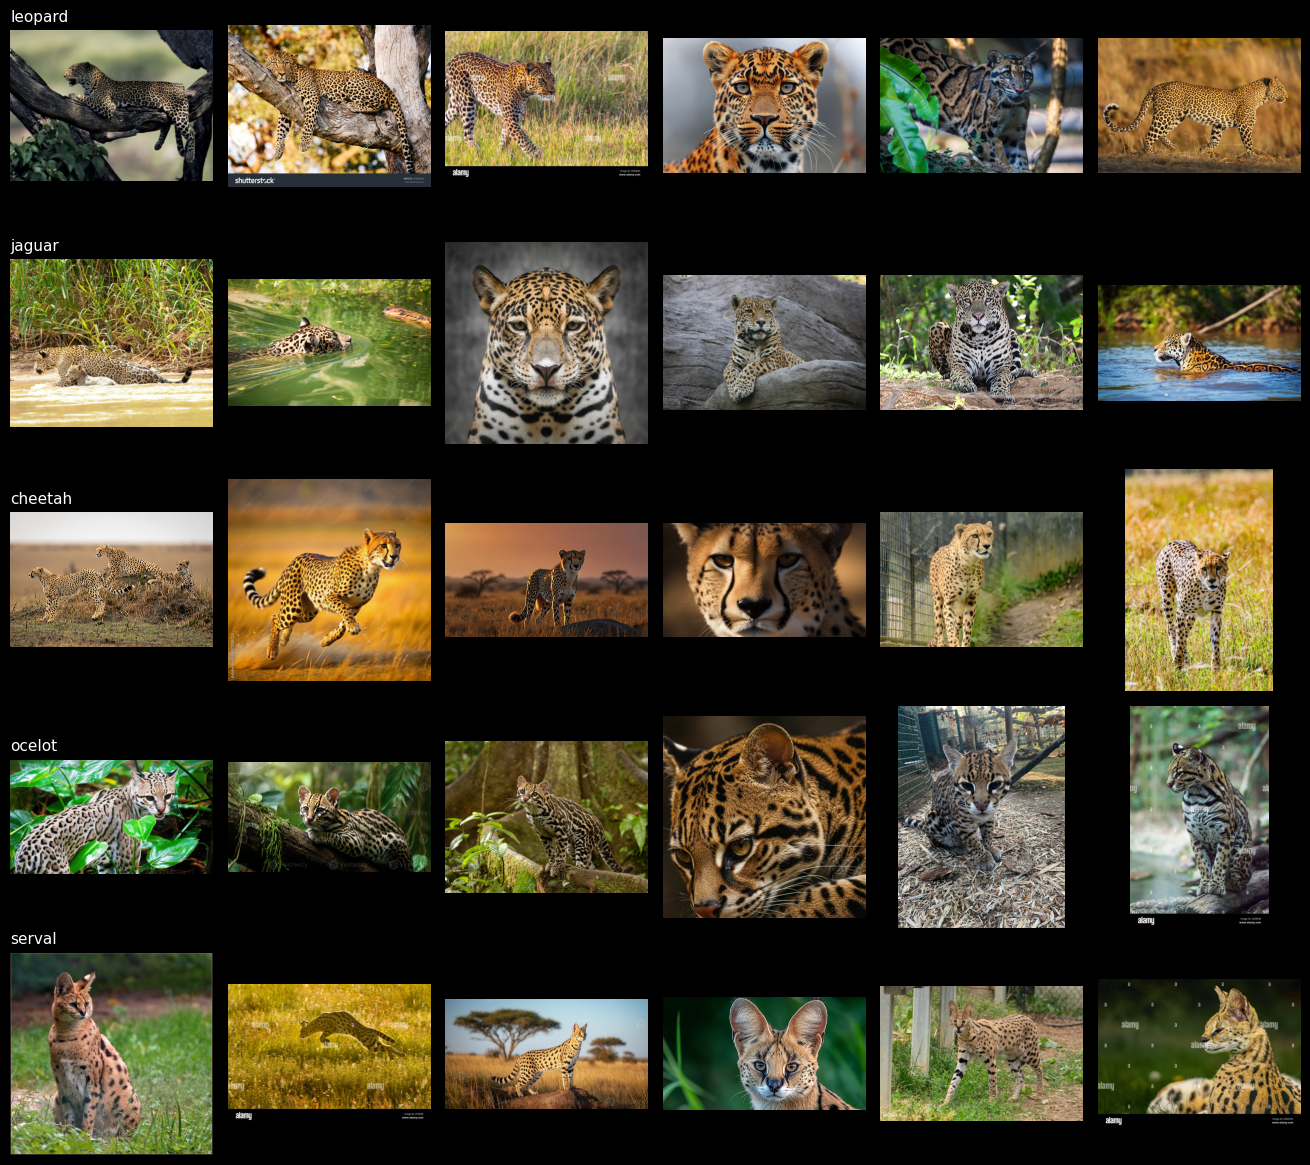

In [9]:
n_show = 6
labels = list(summary['classes'].keys())

fig, axes = plt.subplots(len(labels), n_show, figsize=(2.2 * n_show, 2.4 * len(labels)))
axes = np.atleast_2d(axes)

for r, label in enumerate(labels):
    files = sorted(Path(summary['save_dir'], label).glob('*.jpg'))[:n_show]
    for c in range(n_show):
        ax = axes[r, c]
        ax.axis('off')
        if c < len(files):
            ax.imshow(Image.open(files[c]))
            if c == 0:
                ax.set_title(label, loc='left', fontsize=11)

plt.tight_layout()
plt.show()

## 6. Turning the records into a manifest

`records` has one row per saved image. The manifest is the permanent record of what was collected,
and it matters more here than in a normal project: **search results change over time, so re-running
this scraper later will not give the same dataset.** The manifest is the only reproducible
account of this run.

The prompt requires at least `filename`, `label`, `source_url`, `query`, and a boolean
`readable`. The scraper supplies everything except `readable`, which comes from the integrity pass in
4.1. The scraper also supplies `image_url` (the direct link to the image file, as opposed to
`source_url`, the page it appeared on), `title`, `width` and `height`, which are kept.

The manifest goes to `data/` inside the project folder (`PROJECT_DIR`, set in the first code cell).
The path is written out in full, not left relative to wherever Jupyter happened to start, so the manifest
always lands in the same place. When the project moves into the repo, `PROJECT_DIR` is the one line to
change.

Notebook 2 adds a `kept` column to this file; it does not overwrite it.

In [10]:
manifest = pd.DataFrame(records)

# readable comes from the integrity pass in 4.1: False for every file it deleted
unreadable_keys = {(label, name) for label, name, error in unreadable}
manifest['readable'] = [(l, f) not in unreadable_keys
                        for l, f in zip(manifest['label'], manifest['filename'])]

MANIFEST_PATH = PROJECT_DIR / 'data' / 'P2_manifest.csv'
MANIFEST_PATH.parent.mkdir(parents=True, exist_ok=True)
manifest.to_csv(MANIFEST_PATH, index=False)

print(f'{len(manifest)} rows written to {MANIFEST_PATH}')
manifest[['filename', 'label', 'query', 'source_url', 'readable']].head()

2000 rows written to C:\Users\grego\P2_Images\data\P2_manifest.csv


,filename,label,query,source_url,readable
0,leopard_0000.jpg,leopard,leopard wildlife,https://fity.club/lists/suggestions/Wallpapers...,True
1,leopard_0001.jpg,leopard,leopard resting in tree,https://www.shutterstock.com/image-photo/majes...,True
2,leopard_0002.jpg,leopard,african leopard savanna,https://www.alamy.com/walking-leopard-at-the-s...,True
3,leopard_0003.jpg,leopard,leopard face close up wildlife,https://www.dreamstime.com/leopard-face-extrem...,True
4,leopard_0004.jpg,leopard,leopard in zoo,https://www.pexels.com/photo/clouded-leopard-i...,True


## Review

This notebook built a labeled image dataset of five spotted wild cats from raw search results:

1. **The classes** (`leopard`, `jaguar`, `cheetah`, `ocelot`, `serval`) are separated by coat pattern,
   build and face, and are justified against all four constraints in section 2.2. Two of them (`ocelot`,
   `serval`) are deliberately not ImageNet classes. The prediction for Notebook 3 is that
   **leopard ↔ jaguar** will be the most-confused pair, with **serval ↔ cheetah** second
2. **Five queries per class**, matched across classes by slice (general, behaviour, habitat,
   close-up, zoo), so each class covers the same range of photo types and the zoo slice gives
   all five classes a shared background
3. **The scraper ran as provided**, with every argument justified in section 3. Each class was
   scraped into an empty staging folder, retried automatically when throttled, and saved to disk so that
   re-running the notebook does not change the dataset
4. **Integrity and accounting** opened every saved file and tracked each class from requested to
   downloaded to readable
5. **The manifest** at `data/P2_manifest.csv` is the record of what was collected

**Carried forward:**

- **Notebook 2** removes cars, logos, print fabric, cartoons, game and anime characters, Savannah cats,
  other species and duplicates by hand.
  The duplicate check must compare images *across* classes too: the scraper only drops an exact URL repeated
  within one class, so the same photo can appear in two classes
- **Notebook 3** checks the leopard ↔ jaguar and serval ↔ cheetah predictions against the confusion
  matrix, and compares per-class recall for the ImageNet classes with the two non-ImageNet ones
- **Notebook 4** checks whether the models use the coat or the habitat (rainforest for `jaguar` and
  `ocelot`, savanna for the rest), and whether camera-trap artifacts drive any predictions

**Next:** `P2_Images-2_Preprocessing_<TeamName>.ipynb` turns this folder of search results into
an actual dataset.